In [9]:
import sys
import os
import numpy as np


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import hgm_sep as hgm
from models import clm_sep as clm

In [10]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

In [11]:
# worm_id = np.argmax(np.array([np.sum(discrete_states_gcamp[i]['REV'].values) for i in range(len(filenames_gcamp))]))
worm_id = 24  # 33  # 29

# selection_n = [label for label in traces_gcamp[worm_id].columns if label != '' and label[-1] != '_']
selection_n = ['AVAR', 'ALA', 'VB02', 'IL2L', 'SMDDR', 'RID']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 2
dims_generation = 2

weights = (0.5, 2.)

In [12]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

In [5]:
filenames_art = list()
discrete_states_art = discrete_states_gcamp.copy()
eigenworms_art = eigenworms_gcamp.copy()
neural_modes_art = list()
traces_reconstructed_art = list()
traces_residual_art = list()
traces_art = list()
for i in range(len(filenames_gcamp)):
	(filename_art,
	 neural_modes_art_,
	 traces_reconstructed_art_,
	 traces_residual_art_,
	 traces_art_,
	 params_art_,
	 params_cca_art_) = artificializer.artificialize(weights, hgm,
													 filenames_gcamp[i],
													 traces_gcamp[i].columns,
													 eigenworms_art[i],
													 discrete_states_art[i],
													 n_dimensions=dims_generation)
	filenames_art.append(filename_art)
	neural_modes_art.append(neural_modes_art_)
	traces_reconstructed_art.append(traces_reconstructed_art_)
	traces_residual_art.append(traces_residual_art_)
	traces_art.append(traces_art_)

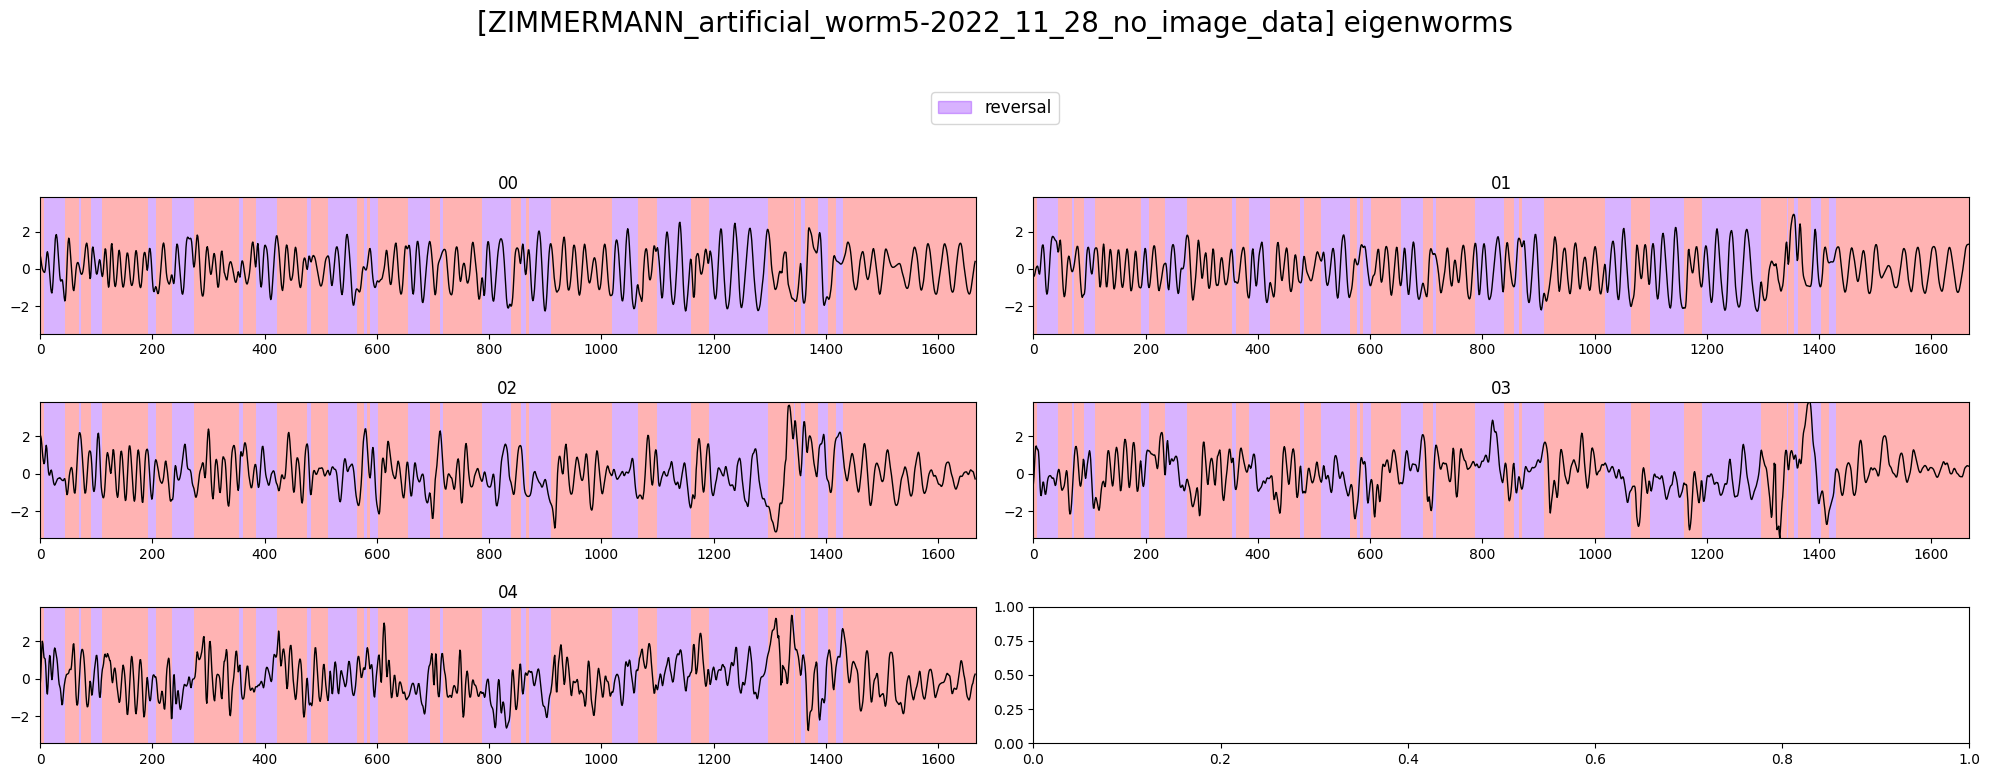

In [6]:
plot_utils.plot_traces(f'[{filenames_art[worm_id]}] eigenworms',
					   discrete_states_art[worm_id]['REV'],
					   eigenworms_art[worm_id],
					   n_plots=None, plots_per_row=2)

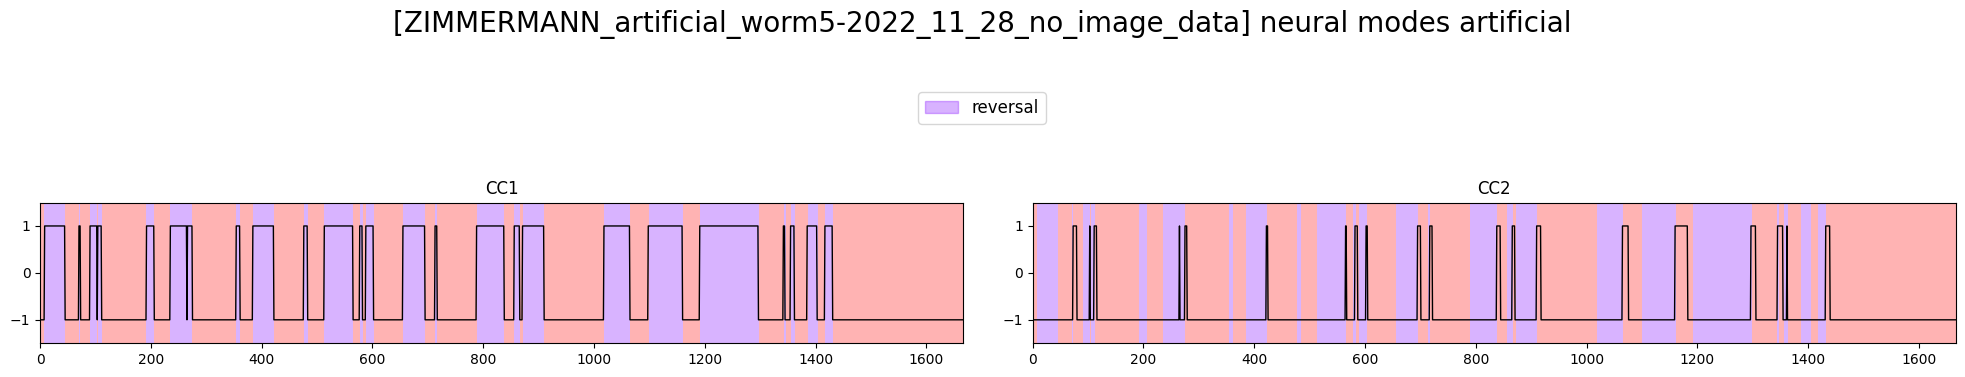

In [7]:
plot_utils.plot_traces(f'[{filenames_art[worm_id]}] neural modes artificial',
					   discrete_states_art[worm_id]['REV'],
					   neural_modes_art[worm_id],
					   n_plots=dims_generation, plots_per_row=2, ylimits=(-1.5, 1.5))

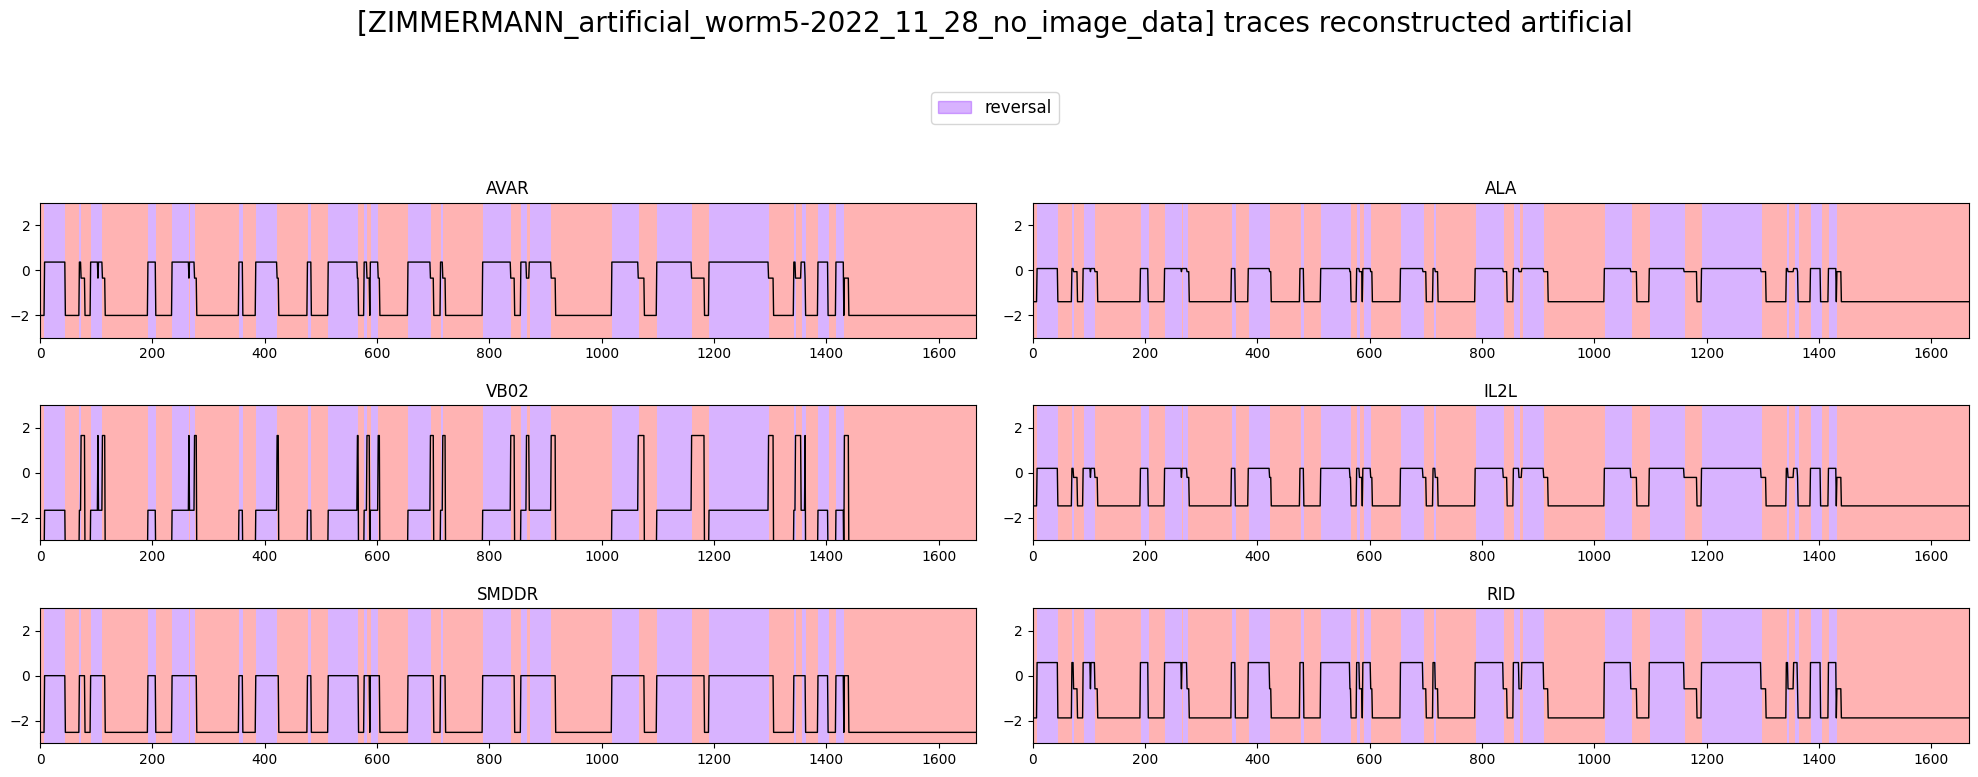

In [8]:
plot_utils.plot_traces(f'[{filenames_art[worm_id]}] traces reconstructed artificial',
					   discrete_states_art[worm_id]['REV'],
					   traces_reconstructed_art[worm_id][selection_n],
					   n_plots=None, plots_per_row=2, ylimits=(-3, 3))

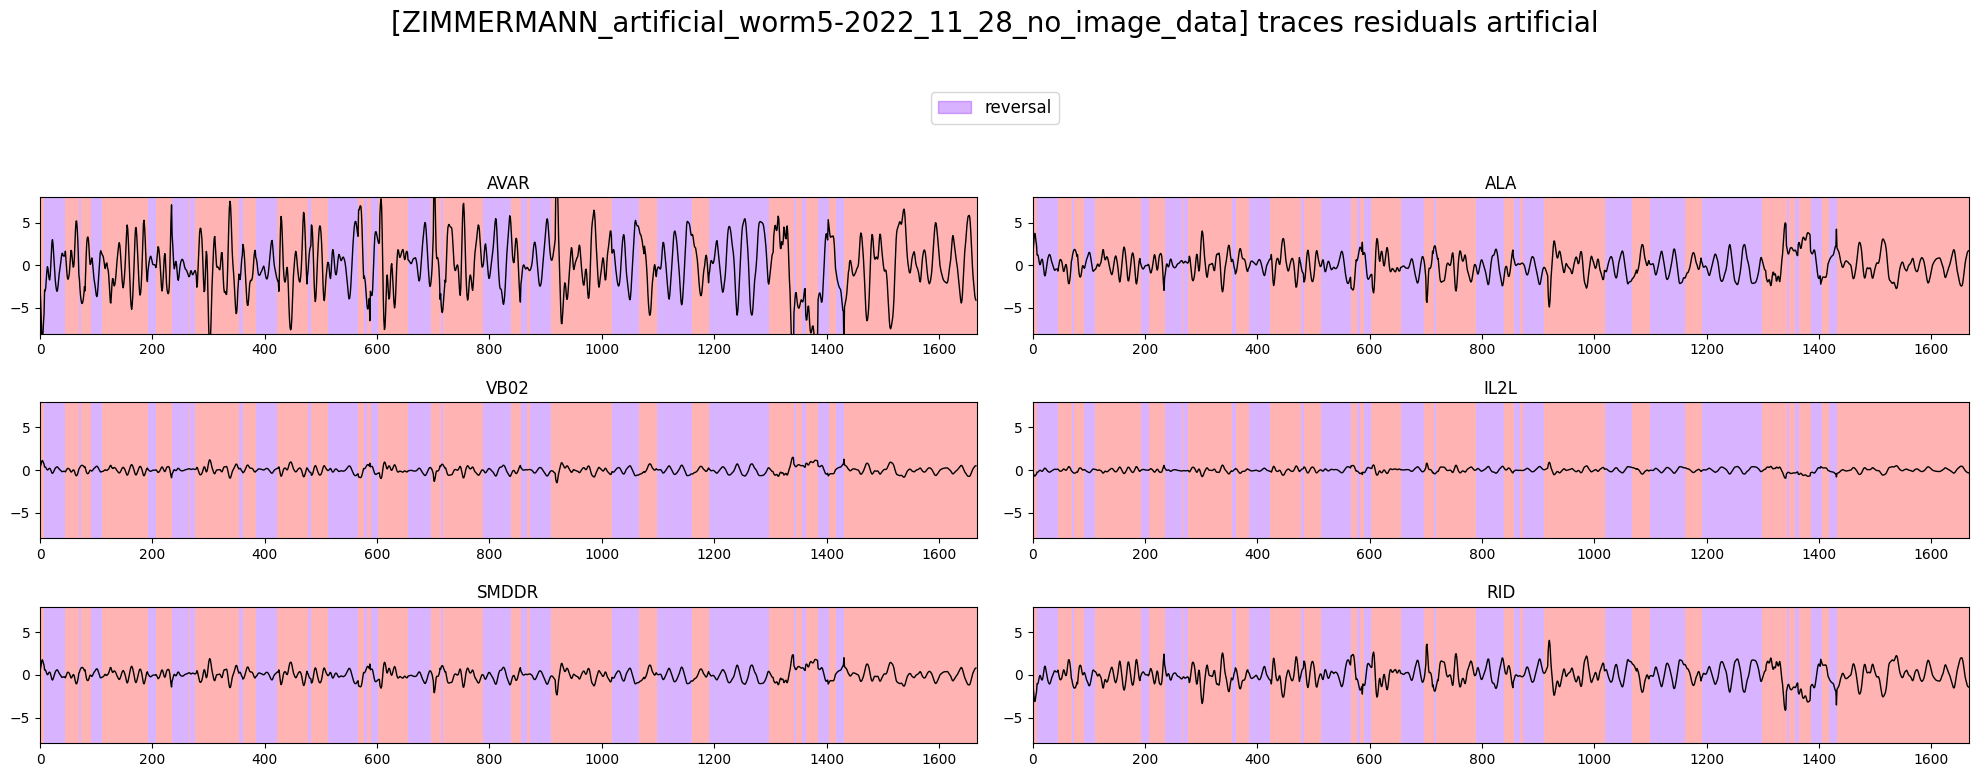

In [9]:
plot_utils.plot_traces(f'[{filenames_art[worm_id]}] traces residuals artificial',
					   discrete_states_art[worm_id]['REV'],
					   traces_residual_art[worm_id][selection_n],
					   n_plots=None, plots_per_row=2, ylimits=(-8, 8))

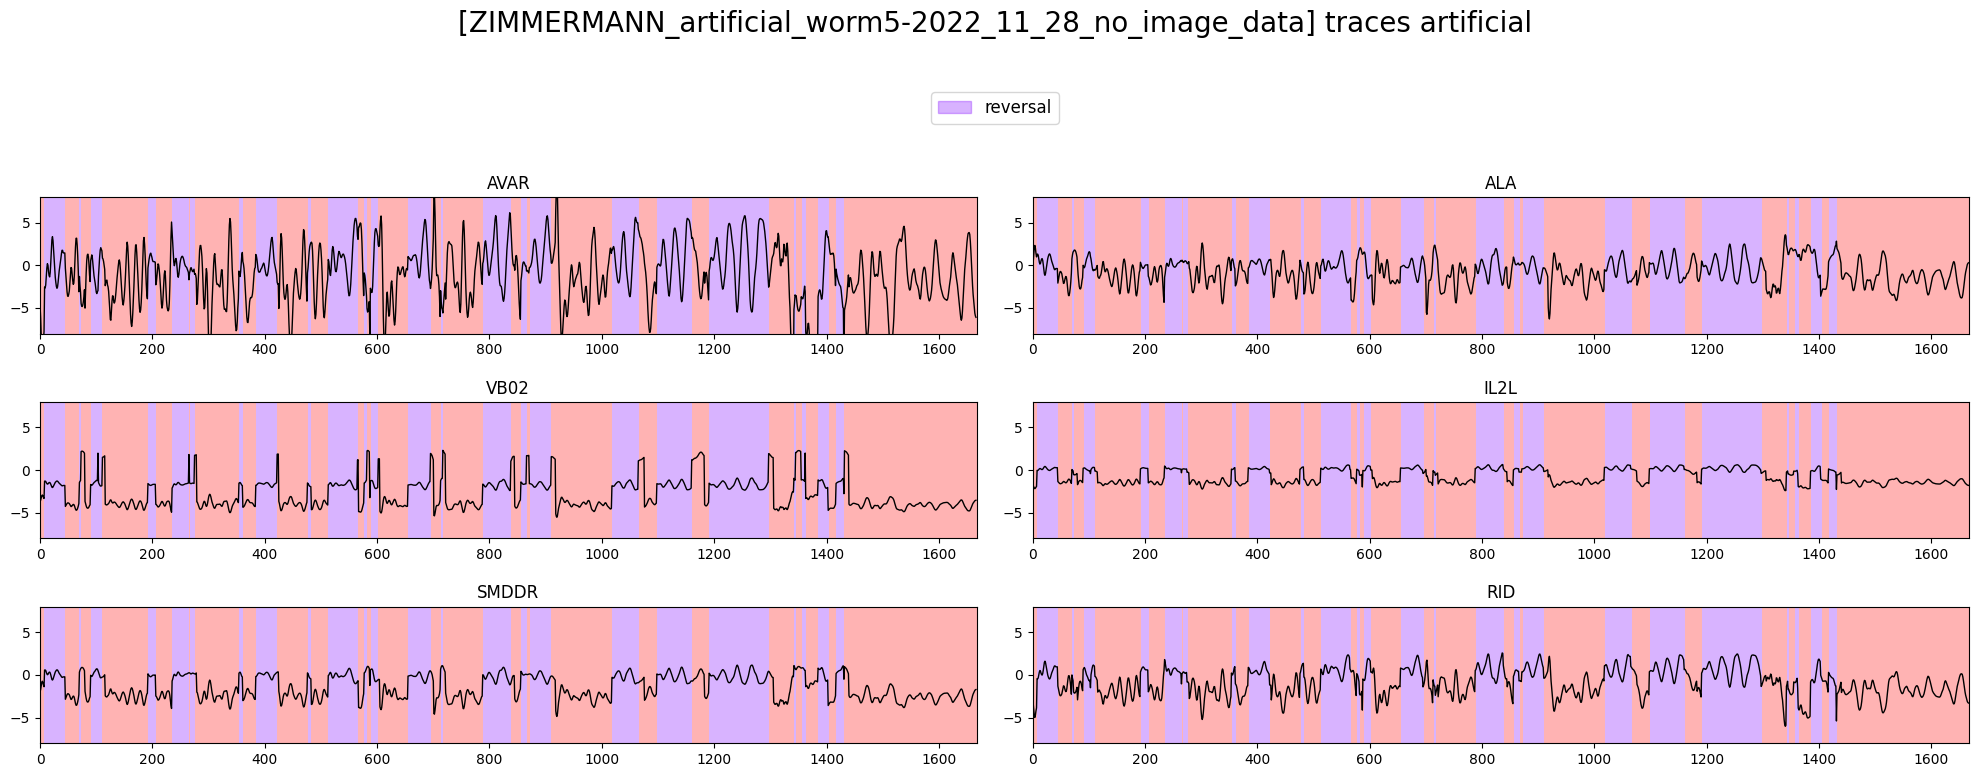

In [10]:
plot_utils.plot_traces(f'[{filenames_art[worm_id]}] traces artificial',
					   discrete_states_art[worm_id]['REV'],
					   traces_art[worm_id][selection_n],
					   n_plots=None, plots_per_row=2, ylimits=(-8, 8))